# GAM – tổng quan

**Câu hỏi:** thêm một hàm trơn theo ngày trong năm vào AnomAR1 (mô hình cộng tổng quát, GAM)
có dự báo diện tích ngập ĐBSCL tốt hơn mốc **AnomAR1** không?

Notebook này là điểm bắt đầu. Mỗi phần chạy hàm thật trong `src/GAM/` và kết thúc bằng
dòng **Chi tiết** chỉ ra file và hàm cần mở khi muốn xem kỹ. Notebook không chứa logic riêng;
kết quả đọc từ `results/GAM/` (sinh bởi `gam_run_model.py`, `gam_analysis.py` và `gam_figures.py`).

In [1]:
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().resolve().parents[1]          # notebooks/GAM -> gốc repo
sys.path.insert(0, str(ROOT / "src" / "GAM"))
TABLES = ROOT / "results" / "GAM" / "tables"
FIGURES = ROOT / "results" / "GAM" / "figures"

from gam_common import load_data, season_index
from gam_model import GAM_GRID, contributions, gam_forecast
from gam_protocol import HORIZONS, HORIZON_DAYS, anom_ar1, build_rows, climatology, rolling_origin

## 1. Kết luận một câu

In [2]:
tests = pd.read_csv(TABLES / "vs_anom_ar1.csv")
for row in tests.itertuples():
    print(f"{HORIZON_DAYS[row.h]:>2} ngày: RMSE GAM / AnomAR1 = {row.rmse_ratio:.3f}, "
          f"thắng {row.wins}/{row.n_seasons} mùa, p Holm = {row.p_t_holm:.4f}, p TOST ±5% = {row.p_tost:.4f}")

 8 ngày: RMSE GAM / AnomAR1 = 1.006, thắng 5/11 mùa, p Holm = 1.0000, p TOST ±5% = 0.0017
16 ngày: RMSE GAM / AnomAR1 = 0.997, thắng 7/11 mùa, p Holm = 1.0000, p TOST ±5% = 0.0530
32 ngày: RMSE GAM / AnomAR1 = 1.001, thắng 7/11 mùa, p Holm = 1.0000, p TOST ±5% = 0.2526


GAM **gần như trùng** AnomAR1: RMSE chênh dưới 1% ở cả ba tầm, không tầm nào khác có ý nghĩa.
Ở 8 ngày có bằng chứng **tương đương** trong biên ±5% RMSE (p TOST < 0,01); ở 16 và 32 ngày chưa đủ
bằng chứng để gọi là tương đương (khoảng tin cậy rộng). Hàm trơn theo ngày không mang lại lợi ích rõ ràng.

## 2. Bản đồ code: đọc theo thứ tự này

| Thứ tự | File | Làm gì |
|---|---|---|
| 0 | `gam_data.py` | Đọc cấu hình vùng và `data/processed/level1_series.csv` thành ma trận 21 mùa × 27 bước |
| 1 | `gam_protocol.py` | Luật chơi chung: climatology, bảng dòng, fold rolling origin, chọn cấu hình, AnomAR1, kiểm định cấp mùa |
| 2 | `gam_model.py` | GAM: ma trận đầu vào, lưới 6 cấu hình, học và dự báo, đọc hệ số |
| – | `gam_common.py` | Hằng số và đường dẫn dùng chung cho các bước |
| 3 | `gam_build_dataset.py` | **Bước 1**: bảng dòng để xem → `data/processed/GAM/` |
| 4 | `gam_run_model.py` | **Bước 2**: dự báo 11 mùa test → `predictions.csv`, cấu hình, hệ số |
| 5 | `gam_analysis.py` | **Bước 3**: `rmse.csv`, `vs_anom_ar1.csv`, bảng theo điều kiện, phần dư, bóc tách |
| 6 | `gam_figures.py` | **Bước 4**: 12 hình |

Chạy lại theo thứ tự bước 1 → 4 (`python src/GAM/<file>.py`); kiểm thử: `python -m pytest tests/GAM`.

## 3. Dữ liệu

Mỗi ảnh MODIS 8 ngày được gộp thành một con số: diện tích ngập (km²) của ĐBSCL.
21 mùa lũ (2000–2020), mỗi mùa 27 ảnh từ ngày 153 đến ngày 361.

Chi tiết: `gam_data.py::load_flood_matrix`

Kích thước: (21, 27) (mùa × bước)


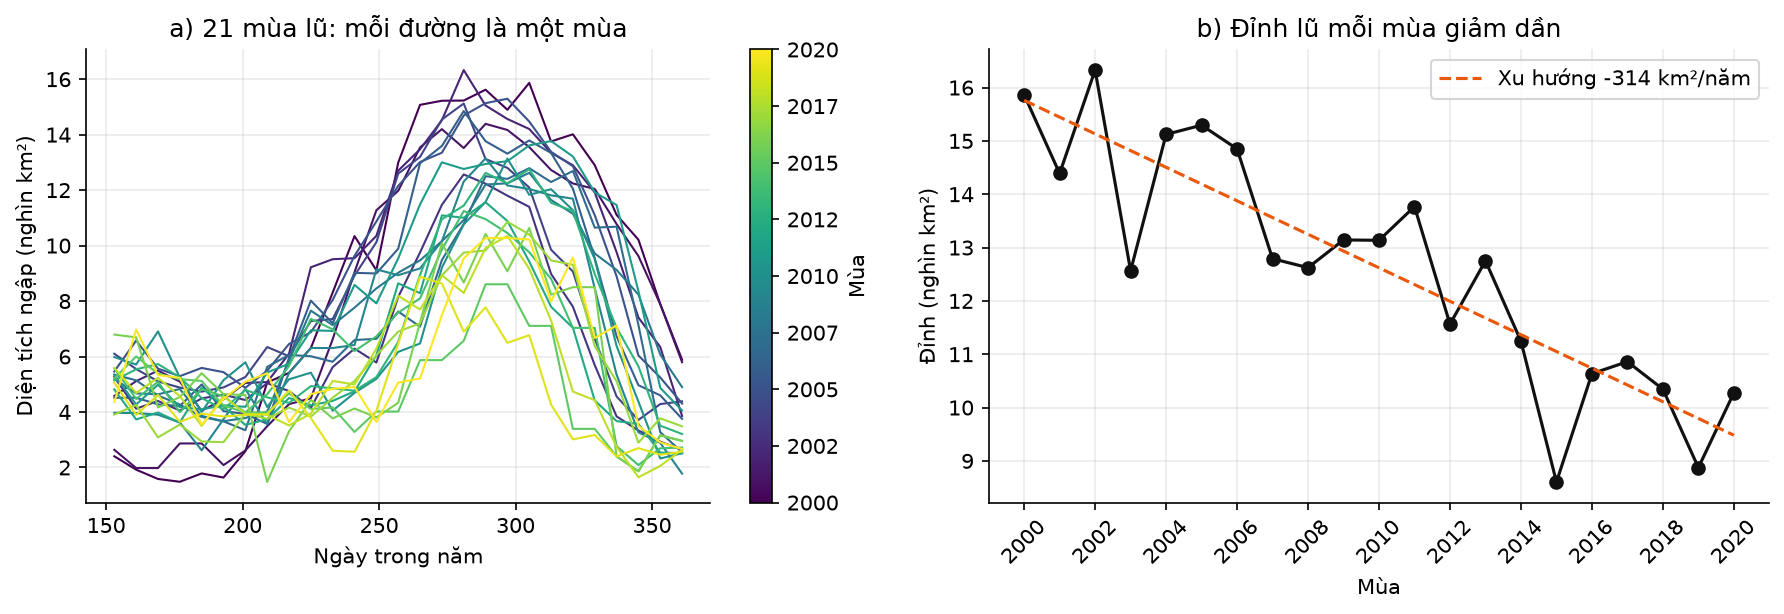

In [3]:
cfg, Y = load_data()
print("Kích thước:", Y.shape, "(mùa × bước)")
display(Image(FIGURES / "fig01_data.png", width=900))

## 4. Luật chơi chống rò rỉ và mô hình

- **Climatology** c của một mùa = trung bình 5 mùa **liền trước**; **anomaly** a = y − c.
- Tại gốc t chỉ biết bước 1..t của mùa test; đích là t + h (h = 1, 2, 4 bước = 8, 16, 32 ngày).
- Mùa test Y học trên các mùa 2003..Y−1. Cấu hình (n_splines, lam) chọn trong lưới 6 cấu hình bằng
  **3 mùa cuối của tập học**, mùa test không bao giờ được nhìn.
- Mô hình: a_{t+h} ≈ β0 + s(ngày đích) + β1·a_t + β2·a_{t−1}; dự báo = c_{t+h} + anomaly dự báo.
  AnomAR1 là trường hợp riêng: không có β0, s(·), β2 và β1 = φ^h.

Chi tiết: `gam_protocol.py::build_rows`, `gam_protocol.py::rolling_origin`, `gam_protocol.py::pick_config`, `gam_model.py::fit_gam`

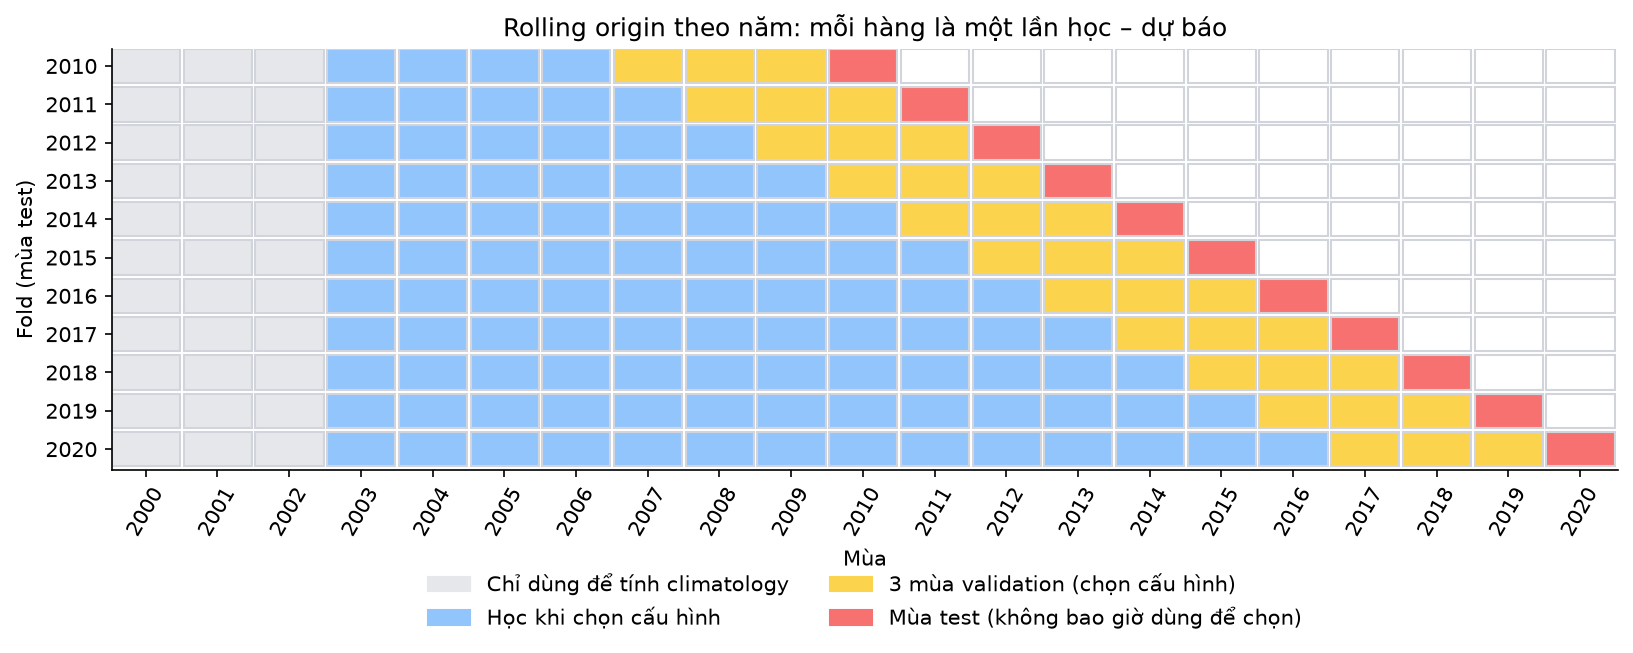

Lưới cấu hình (n_splines, lam): [(6, 0.1), (6, 1.0), (8, 0.6), (8, 5.0), (12, 1.0), (12, 10.0)]


In [4]:
display(Image(FIGURES / "fig02_protocol.png", width=900))
print("Lưới cấu hình (n_splines, lam):", GAM_GRID)

## 5. Một dự báo làm tay: mùa 2015, gốc t = 10, tầm 16 ngày

1. Lấy fold của mùa test 2015 (học 2003–2014), dựng bảng dòng ở h = 2.
2. Chọn cấu hình bằng 3 mùa cuối của tập học, học lại trên đủ tập học, dự báo mùa 2015.
3. Tách dự báo ở gốc t = 10 thành từng phần cộng lại.
4. So với dòng tương ứng trong `predictions.csv`: phải trùng.

Chi tiết: `gam_model.py::gam_forecast`, `gam_model.py::contributions`

In [5]:
season, origin, h = 2015, 10, 2
fold = next(f for f in rolling_origin(cfg) if f.test_season == season)
train = build_rows(Y, cfg, season_index(cfg, fold.train_seasons), h)
test = build_rows(Y, cfg, season_index(cfg, [season]), h)
fit = gam_forecast(train, test, h)
print("Mùa học:", fold.train_seasons[0], "–", fold.train_seasons[-1], "| cấu hình chọn:", fit.config)
print("MSE validation của 6 cấu hình:", [round(m) for m in fit.val_mse])

row = test["t"] == origin
display(contributions(fit.model, test[row]).round(1))
saved = pd.read_csv(TABLES / "predictions.csv")
for model, value in (("gam", fit.pred[row.to_numpy()][0]), ("anom_ar1", anom_ar1(train, test[row], h)[0])):
    in_table = saved.query("model == @model and season == @season and t == @origin and h == @h")["pred"].item()
    print(f"{model:<9} làm tay {value:8.1f} | trong bảng {in_table:8.1f} | khớp: {abs(value - in_table) < 1e-6}")

Mùa học: 2003 – 2014 | cấu hình chọn: (6, 1.0)
MSE validation của 6 cấu hình: [1631650, 1549396, 1637702, 1560680, 1690406, 1619915]


,c_target,beta0,s_doy,beta1_a_t,beta2_a_t1,pred
0,5796.1,22.4,-413.0,-1310.4,39.5,4134.7


gam       làm tay   4134.7 | trong bảng   4134.7 | khớp: True
anom_ar1  làm tay   4385.3 | trong bảng   4385.3 | khớp: True


## 6. Kết quả tổng

RMSE gộp mọi dự báo của 11 mùa test (2010–2020). Kiểm định so sánh ở **cấp mùa** (n = 11).
`gam_w7` và `anom_ar1_w7` chỉ học 7 mùa gần nhất; phép so sánh cùng lượng dữ liệu nằm ở `gam_w7_vs_anom_ar1_w7.csv`.

Chi tiết: `gam_analysis.py::rmse_table`, `gam_analysis.py::versus_baseline`

,1,2,4
model,,,
gam,1096.0,1372.0,1688.0
anom_ar1,1090.0,1375.0,1687.0
gam_w7,1090.0,1378.0,1711.0
anom_ar1_w7,1084.0,1355.0,1682.0
clim5,1812.0,1845.0,1916.0
persistence,1312.0,2068.0,3456.0


,model,h,n_seasons,rmse_ratio,wins,mse_diff_pct,mse_diff_pct_ci_low,mse_diff_pct_ci_high,p_t,p_wilcoxon,p_tost,p_t_holm
0,gam,1,11,1.0058,5,2.2118,-2.7918,7.2155,0.5076,0.7646,0.0017,1.0
1,gam,2,11,0.9973,7,2.0291,-10.4721,14.5304,0.9137,0.6377,0.0530,1.0
2,gam,4,11,1.0006,7,9.4050,-23.0392,41.8493,0.9896,0.7002,0.2526,1.0


,model,h,n_seasons,rmse_ratio,wins,mse_diff_pct,mse_diff_pct_ci_low,mse_diff_pct_ci_high,p_t,p_wilcoxon,p_tost,p_t_holm
0,gam_w7,1,11,1.0064,5,2.6888,-4.0632,9.4407,0.6975,0.6377,0.0131,1.0
1,gam_w7,2,11,1.0171,6,6.6842,-12.8272,26.1957,0.6621,0.7646,0.2135,1.0
2,gam_w7,4,11,1.0171,6,8.7693,-23.3380,40.8767,0.7730,0.8984,0.2346,1.0


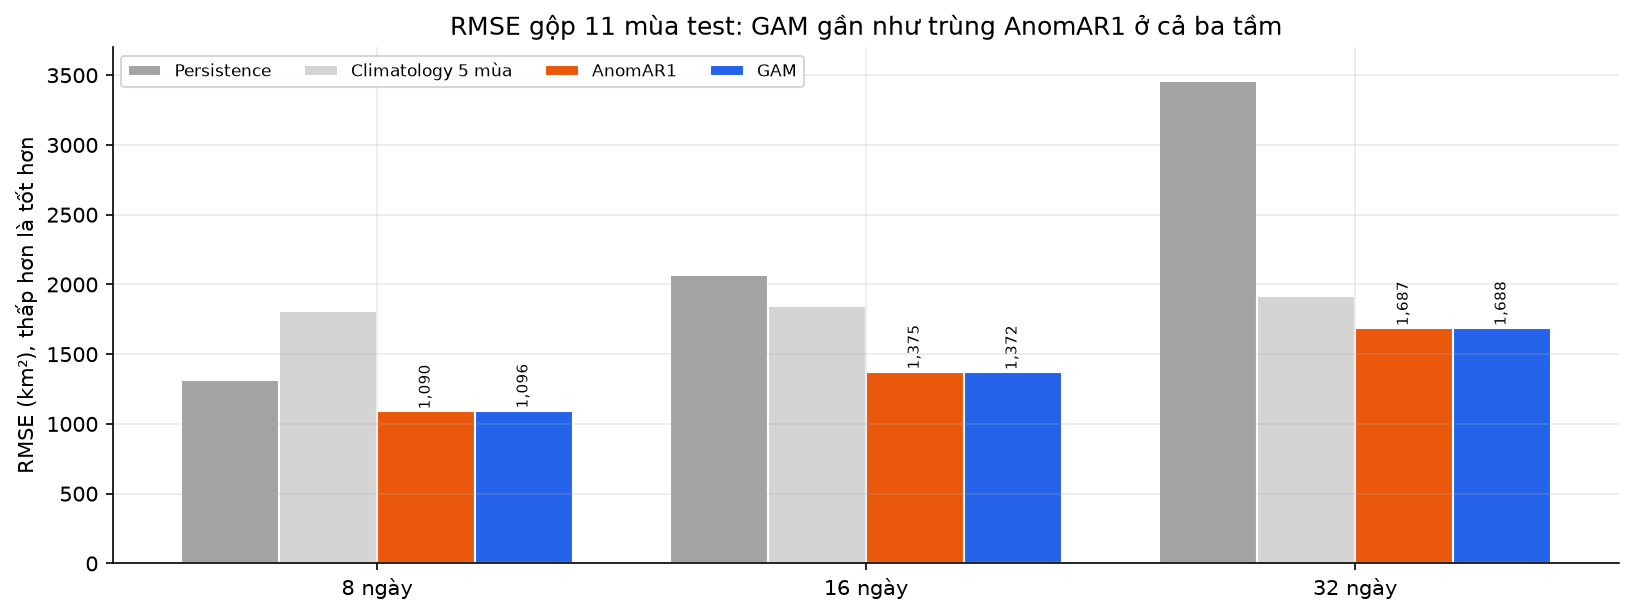

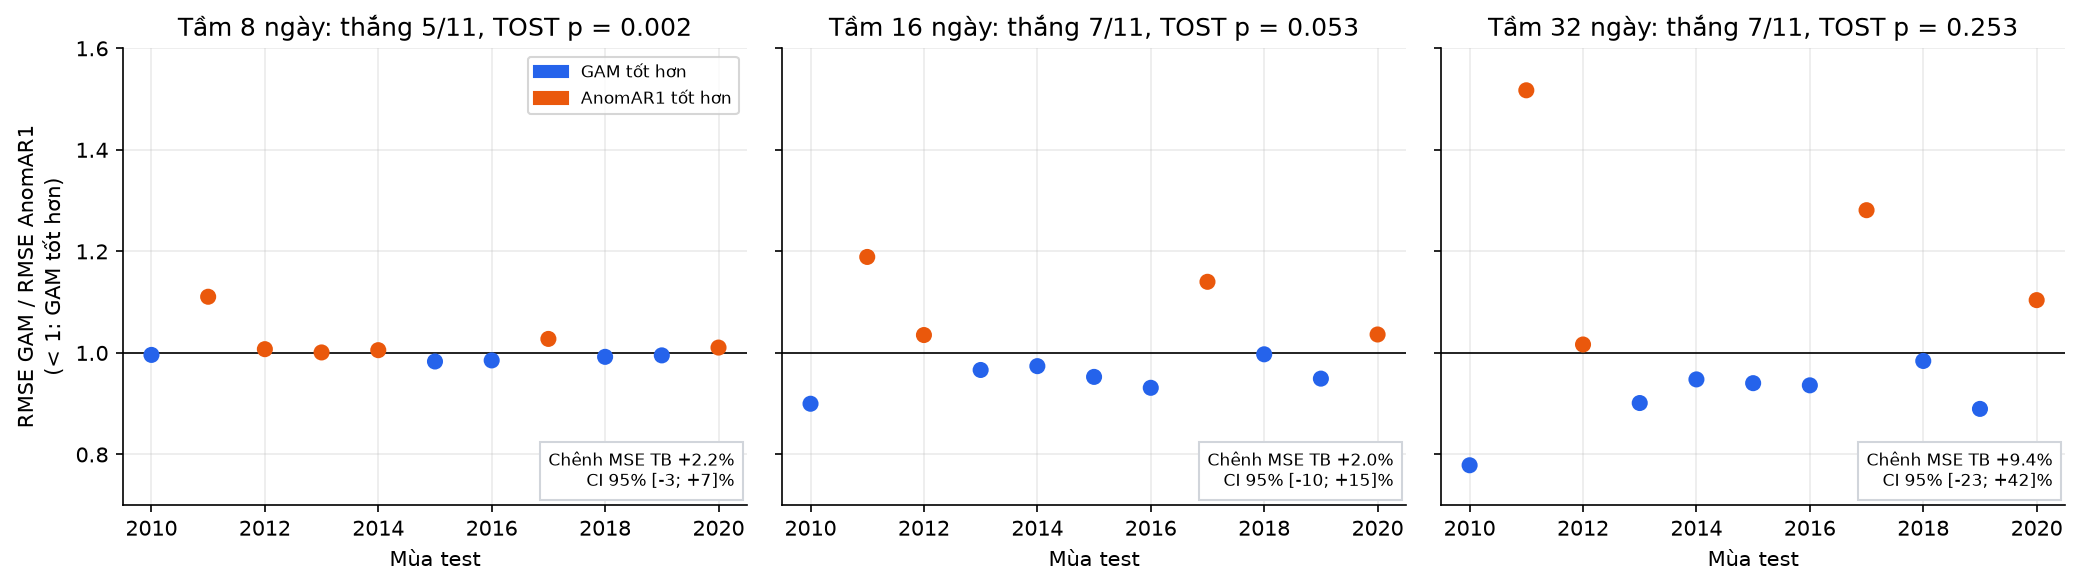

In [6]:
display(pd.read_csv(TABLES / "rmse.csv").set_index("model"))
display(tests)
display(pd.read_csv(TABLES / "gam_w7_vs_anom_ar1_w7.csv").round(4))
display(Image(FIGURES / "fig07_rmse.png", width=700))
display(Image(FIGURES / "fig08_season_ratio.png", width=900))

## 7. Theo điều kiện

GAM khá hơn AnomAR1 khi **nước lên**, nhất là ở 32 ngày (RMSE 1.251 so với 1.357), nhưng kém hơn một chút
ở đỉnh và khi nước rút; hai phần bù trừ nên RMSE gộp gần như bằng nhau.

Chi tiết: `gam_analysis.py::condition_table`, `gam_analysis.py::season_table`

rising    peak  falling
h model                               
1 gam           886.0  1096.0   1311.0
  anom_ar1      897.0  1068.0   1304.0
  gam_w7        865.0  1096.0   1316.0
  anom_ar1_w7   887.0  1061.0   1302.0
  clim5        1214.0  1838.0   2340.0
  persistence   854.0  1420.0   1656.0
2 gam          1121.0  1408.0   1584.0
  anom_ar1     1154.0  1391.0   1578.0
  gam_w7       1086.0  1393.0   1637.0
  anom_ar1_w7  1137.0  1356.0   1564.0
  clim5        1258.0  1838.0   2340.0
  persistence  1099.0  2323.0   2624.0
4 gam          1251.0  1708.0   1981.0
  anom_ar1     1357.0  1692.0   1927.0
  gam_w7       1228.0  1631.0   2091.0
  anom_ar1_w7  1358.0  1668.0   1931.0
  clim5        1365.0  1838.0   2340.0
  persistence  1278.0  3887.0   4311.0

small  medium   large
h model                              
1 gam          1175.0  1194.0   923.0
  anom_ar1     1179.0  1196.0   896.0
  gam_w7       1163.0  1165.0   948.0
  anom_ar1_w7  1169.0  1184.0   900.0
  clim5        2065.0  1448.0  1787.0
  persistence  1230.0  1452.0  1282.0
2 gam          1460.0  1334.0  1307.0
  anom_ar1     1488.0  1367.0  1260.0
  gam_w7       1457.0  1334.0  1329.0
  anom_ar1_w7  1466.0  1342.0  1245.0
  clim5        2105.0  1474.0  1818.0
  persistence  1830.0  2154.0  2220.0
4 gam          1826.0  1413.0  1734.0
  anom_ar1     1885.0  1400.0  1675.0
  gam_w7       1822.0  1474.0  1761.0
  anom_ar1_w7  1886.0  1389.0  1667.0
  clim5        2195.0  1503.0  1893.0
  persistence  2984.0  3458.0  3869.0

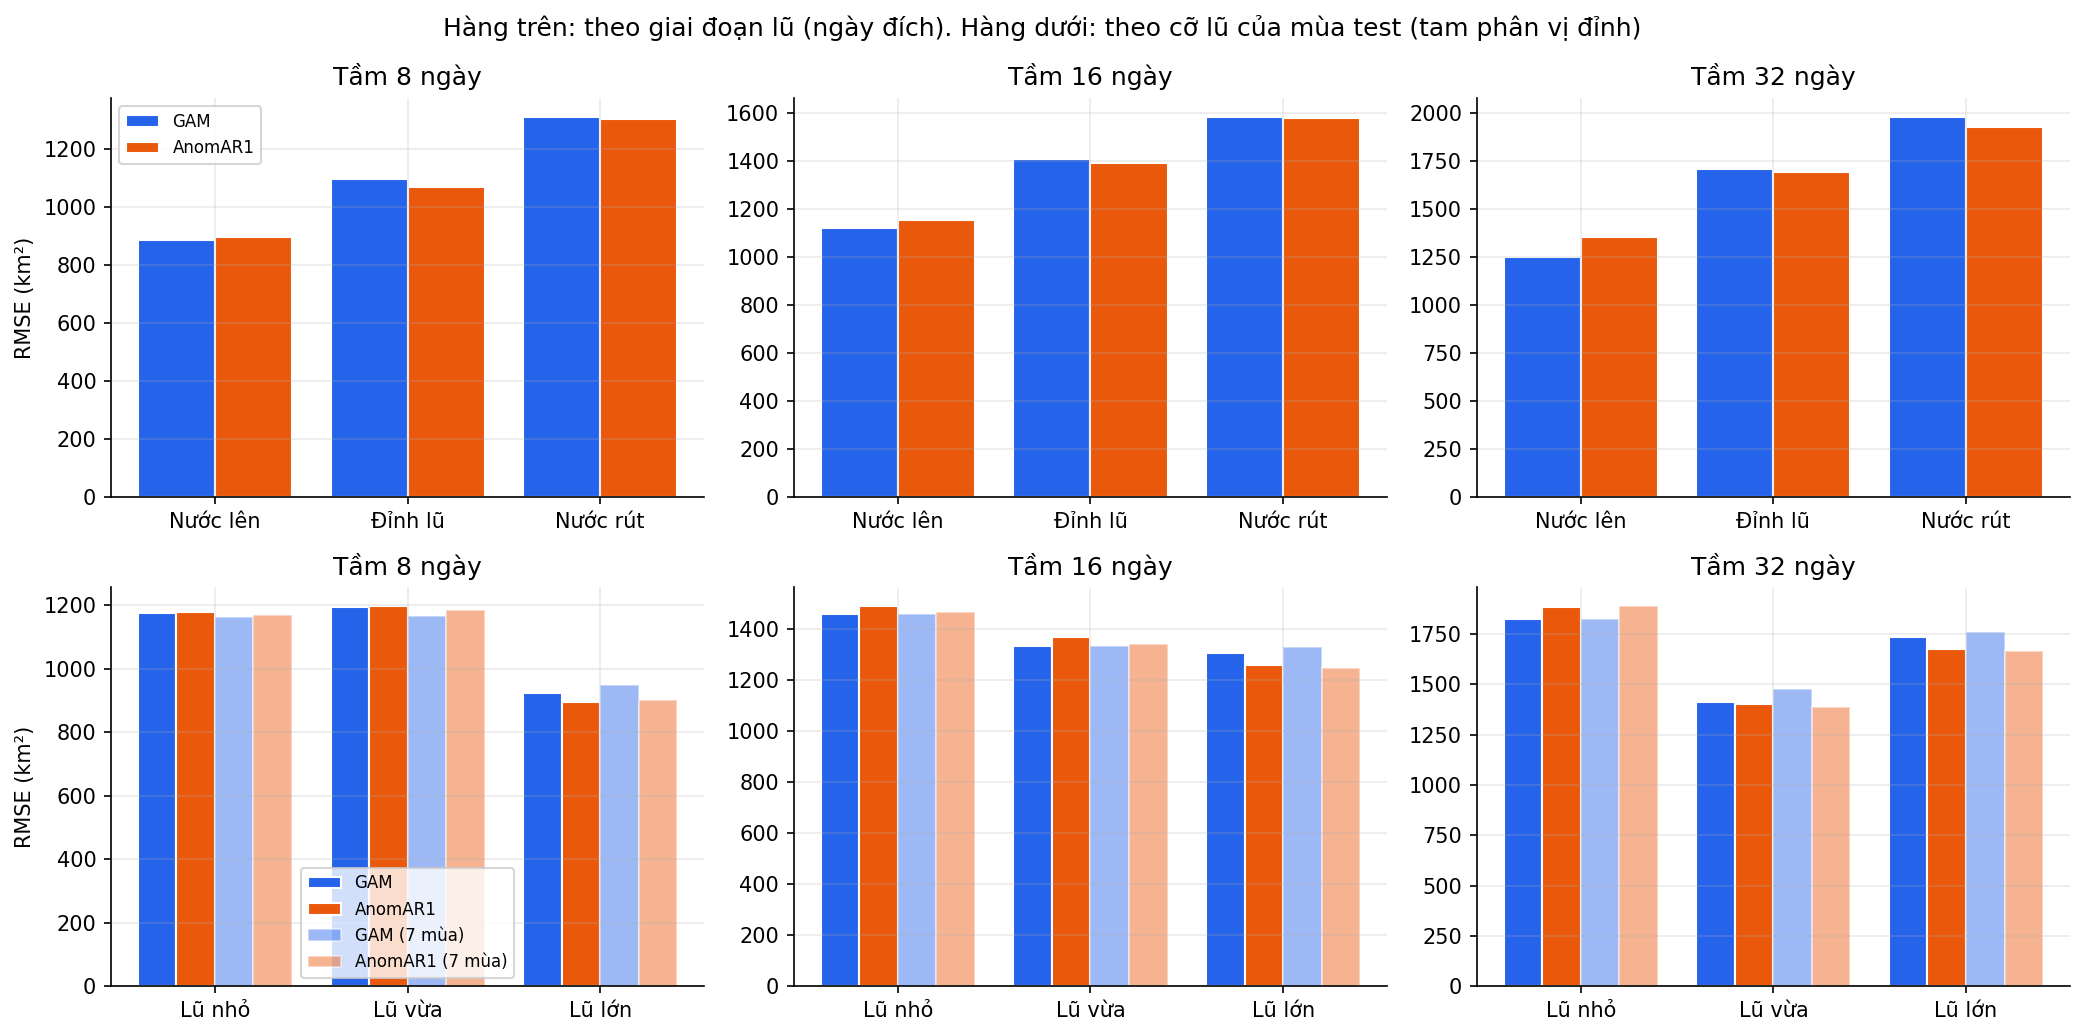

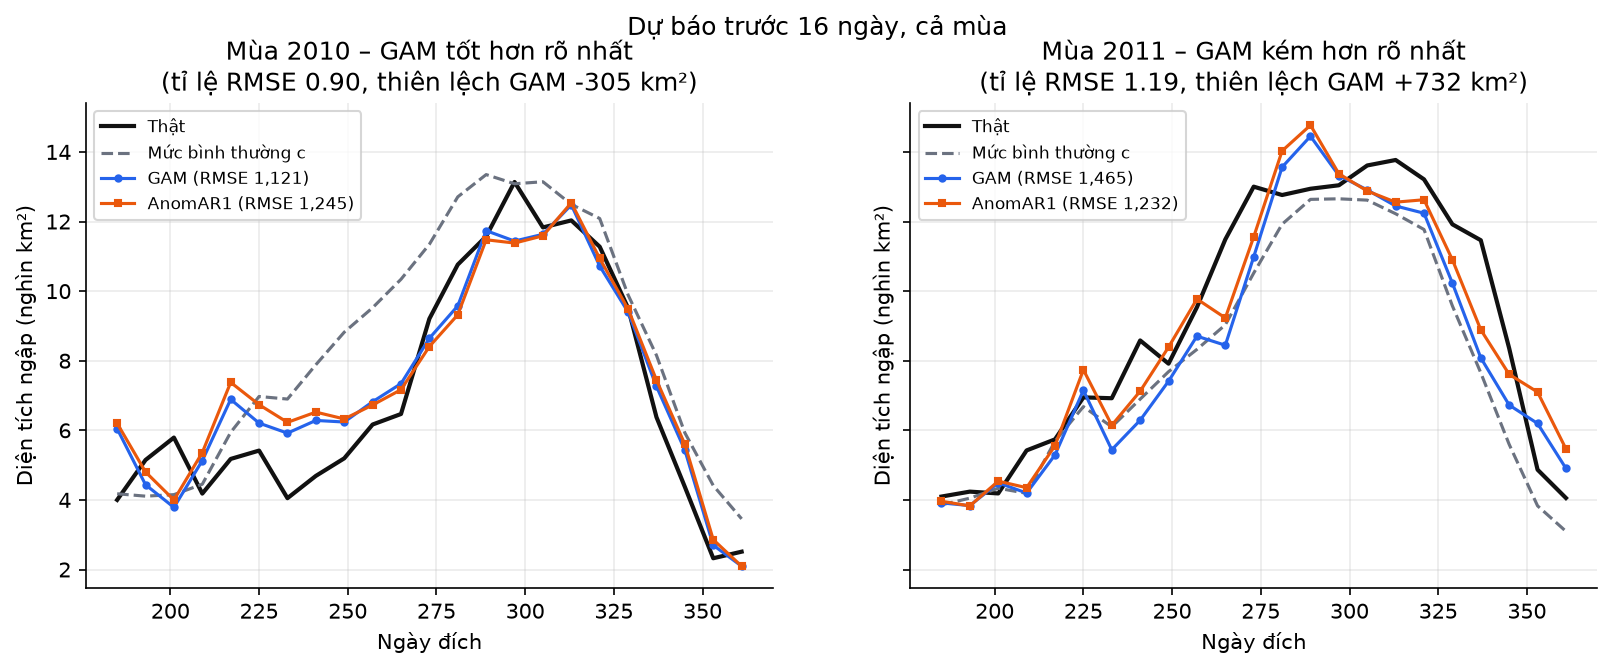

In [7]:
display(pd.read_csv(TABLES / "rmse_by_phase.csv").set_index(["h", "model"]))
display(pd.read_csv(TABLES / "rmse_by_size.csv").set_index(["h", "model"]))
display(Image(FIGURES / "fig09_conditions.png", width=900))
display(Image(FIGURES / "fig11_two_seasons.png", width=900))

## 8. Kiểm tra phụ: GAM học được gì

- **Hệ số:** β1 (trọng số của anomaly hôm nay) giảm theo tầm (khoảng 0,89 → 0,74 → 0,62), đúng như φ^h của AnomAR1;
  β2 gần 0. Hàm trơn s(ngày) có bậc tự do hiệu dụng khoảng 4.
- **Vì sao s(ngày) có hình đó:** climatology 5 mùa trước bị **cao** từ khoảng ngày 230 trở đi (anomaly trung bình
  khoảng −900 km²), vì đỉnh lũ giảm khoảng 314 km² mỗi năm. s(ngày) học phần sửa lệch này.
- **Bóc tách (làm sau khi đã thấy kết quả test, chỉ để hiểu, không vào bảng chính):** bỏ hẳn hàm trơn, chỉ giữ
  β0 + β1·a_t, cho RMSE thấp hơn GAM ở cả ba tầm. Phần trơn theo ngày không phải nguồn lợi ích.

Chi tiết: `gam_model.py::coefficients`, `gam_model.py::seasonal_curve`, `gam_analysis.py::climatology_bias`, `gam_run_model.py::ablation_variants`

,beta0_intercept,beta1_a_t,beta2_a_t1,edof_smooth
h,,,,
1,28.867,0.892,-0.055,3.761
2,-3.831,0.743,-0.045,4.233
4,-210.306,0.615,-0.102,3.689


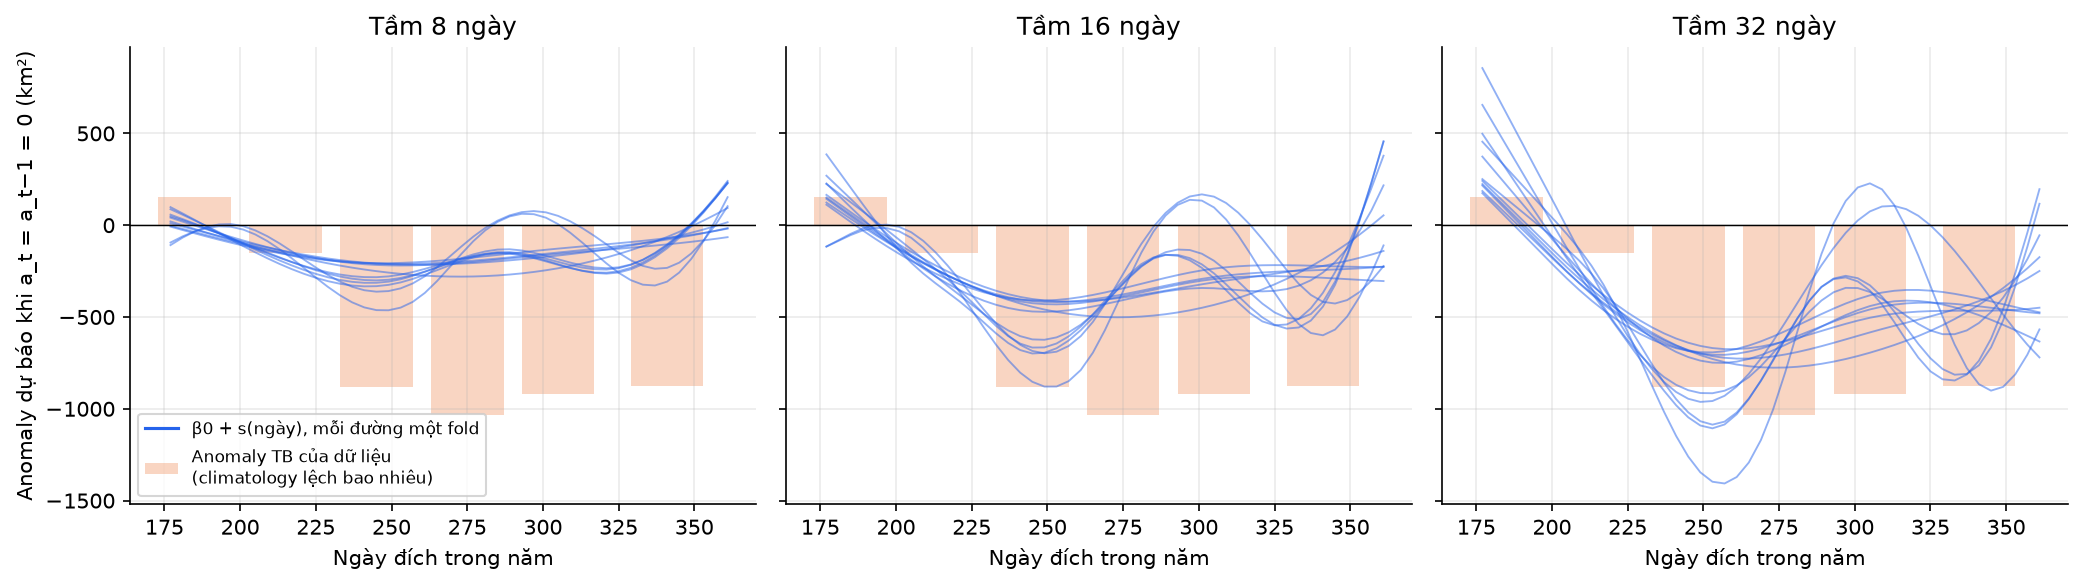

,model,h,h_days,rmse,wins_vs_gam,n_seasons
0,gam,1,8,1095.9,NaN,11
1,anom_ar1,1,8,1089.6,6.0,11
2,gam_linear_doy,1,8,1090.8,7.0,11
3,ar1_direct_intercept,1,8,1080.3,10.0,11
4,gam,2,16,1371.7,NaN,11
5,anom_ar1,2,16,1375.4,4.0,11
6,gam_linear_doy,2,16,1350.1,6.0,11
7,ar1_direct_intercept,2,16,1337.3,7.0,11
8,gam,4,32,1688.2,NaN,11
9,anom_ar1,4,32,1687.1,4.0,11


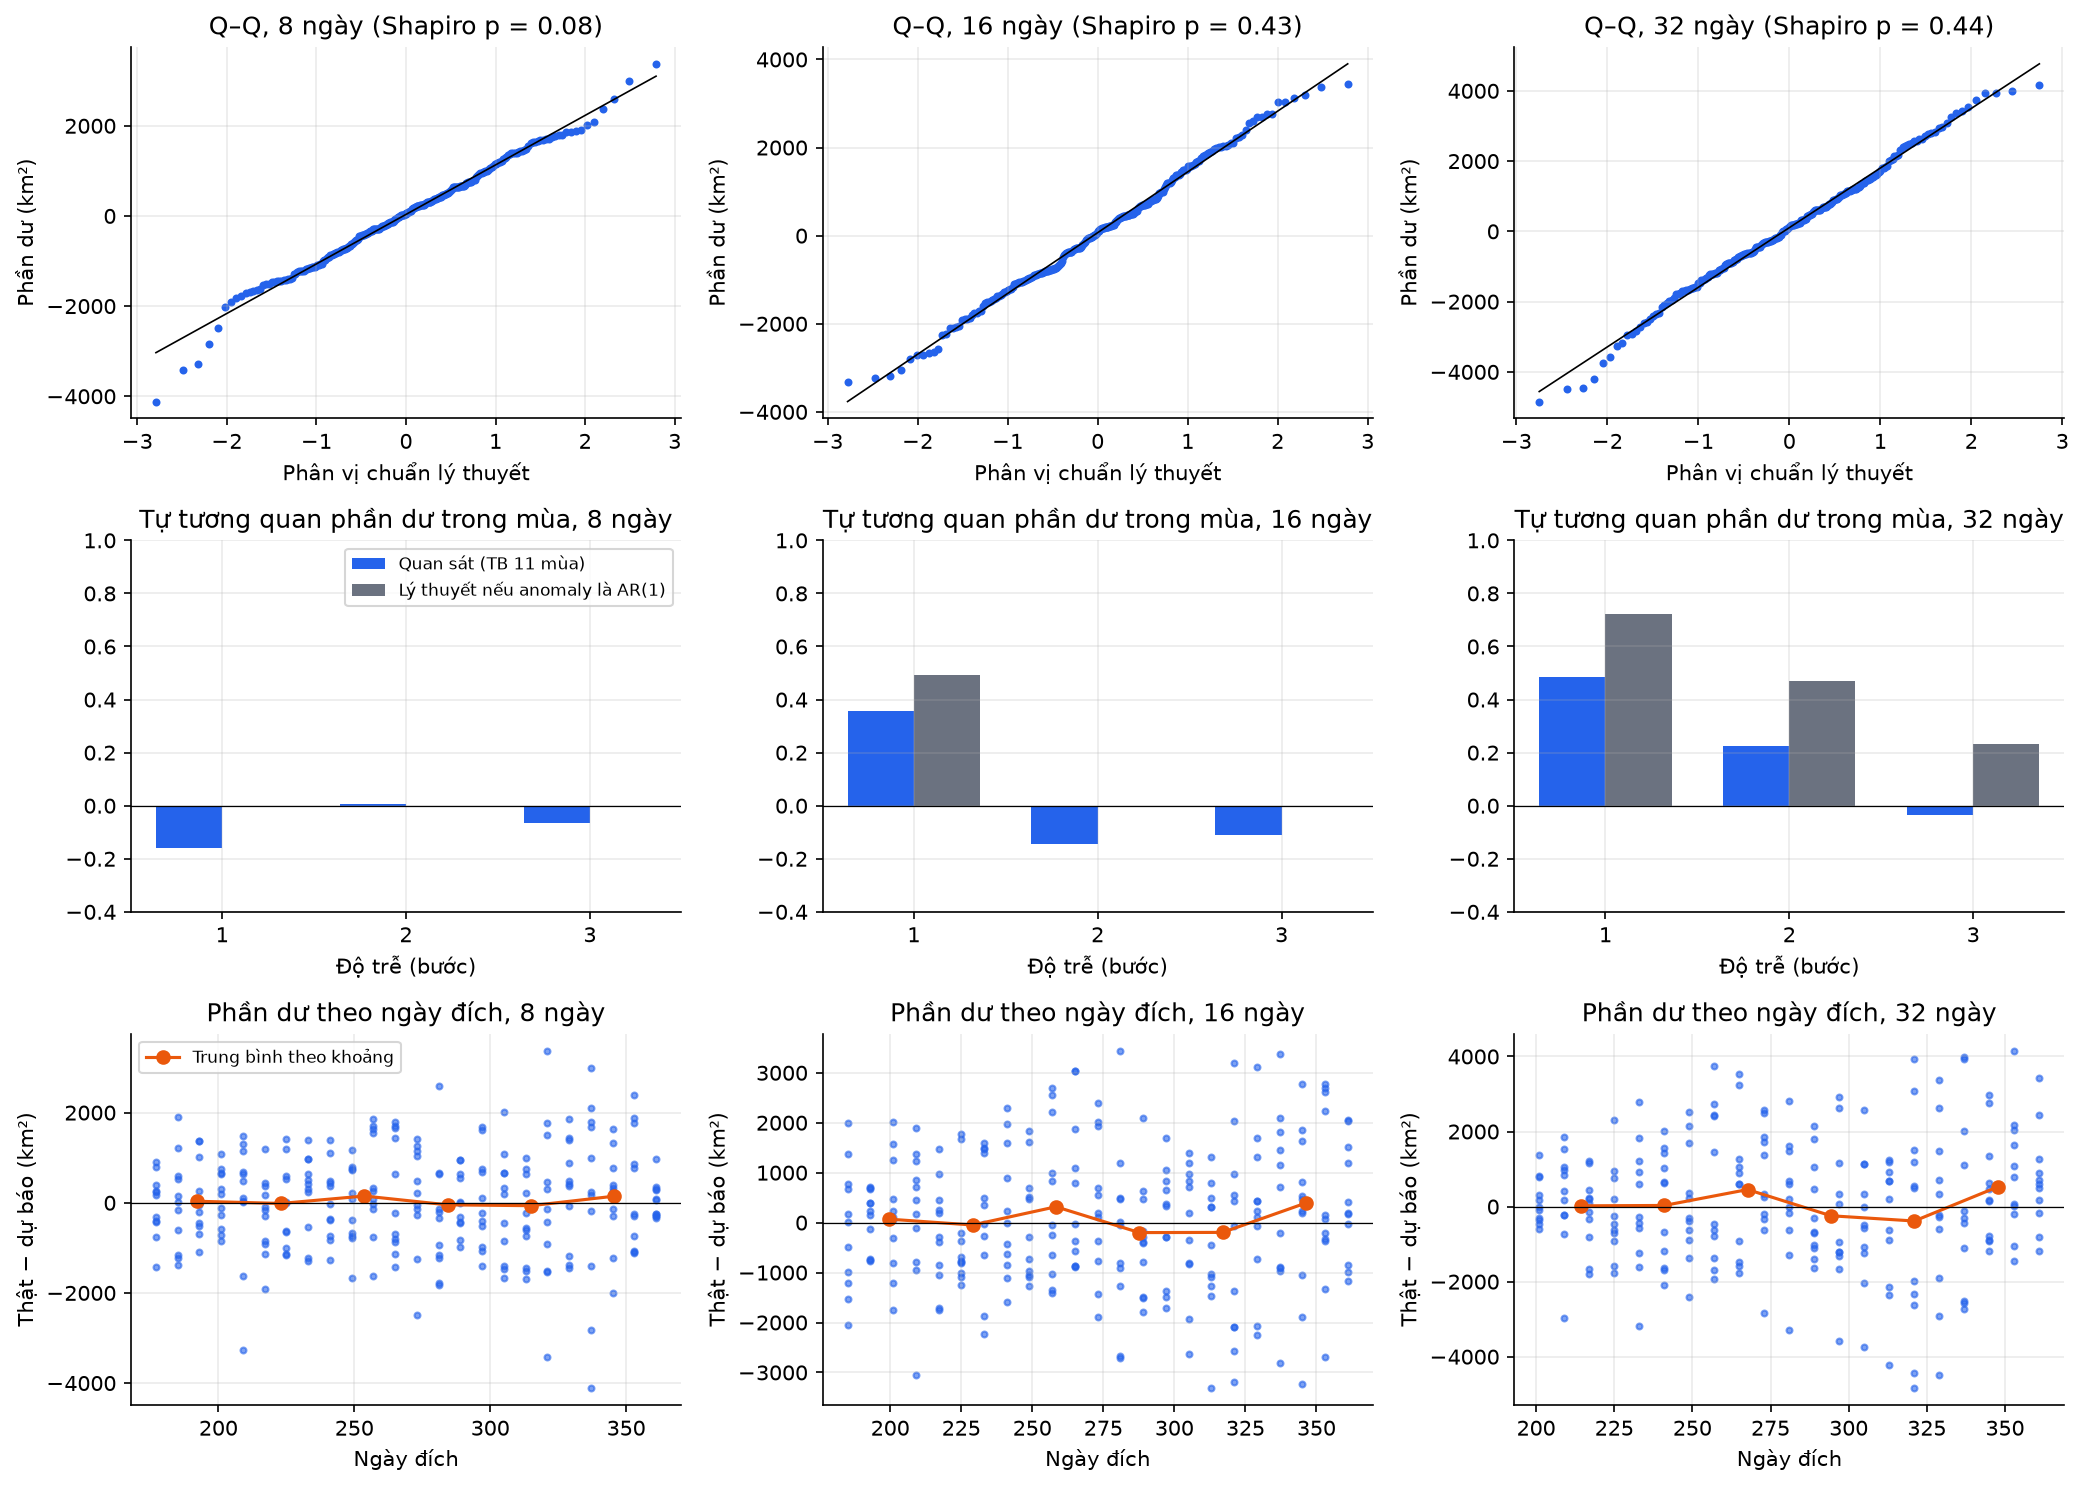

In [8]:
coefs = pd.read_csv(TABLES / "gam_coefficients.csv").query("model == 'gam'")
display(coefs.groupby("h")[["beta0_intercept", "beta1_a_t", "beta2_a_t1", "edof_smooth"]].mean().round(3))
display(Image(FIGURES / "fig06_seasonal_curve.png", width=900))
display(pd.read_csv(TABLES / "gam_ablation_rmse.csv").round(1))
display(Image(FIGURES / "fig10_residuals.png", width=900))

## 9. Cách nói an toàn và hạn chế

- Nói: "Trên 11 mùa test, GAM không khác AnomAR1 có ý nghĩa ở tầm nào; ở 8 ngày hai mô hình tương đương trong ±5% RMSE."
  Không nói "GAM tốt hơn ở nước lên" như một kết luận: bảng theo điều kiện chỉ để mô tả, không kiểm định.
- p Holm ở đây chỉ hiệu chỉnh trong 3 tầm của GAM; bảng tổng hợp của nhóm dùng họ lớn hơn nên p sẽ lớn hơn.
- "Không khác có ý nghĩa" ở 16 và 32 ngày **không** có nghĩa là tương đương (p TOST > 0,05).
- Thí nghiệm bóc tách nghĩ ra sau khi xem kết quả test: muốn dùng biến thể nào phải khai báo trước và chạy lại cho cả nhóm.
- Chỉ 11 mùa test, một chuỗi toàn vùng; mục tiêu là sản phẩm suy diễn từ ảnh MODIS (Vu et al. 2022).

Xem thêm: `src/GAM/README.md`.